In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Advertising.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (200, 5)


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [2]:
print("Dataset Information:")
print("-" * 40)

df.info()

Dataset Information:
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [3]:
print("Missing Values:")
print("-" * 40)

print(df.isnull().sum())

Missing Values:
----------------------------------------
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [5]:
print("Statistical Summary:")
print("-" * 40)

df.describe()

Statistical Summary:
----------------------------------------


,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


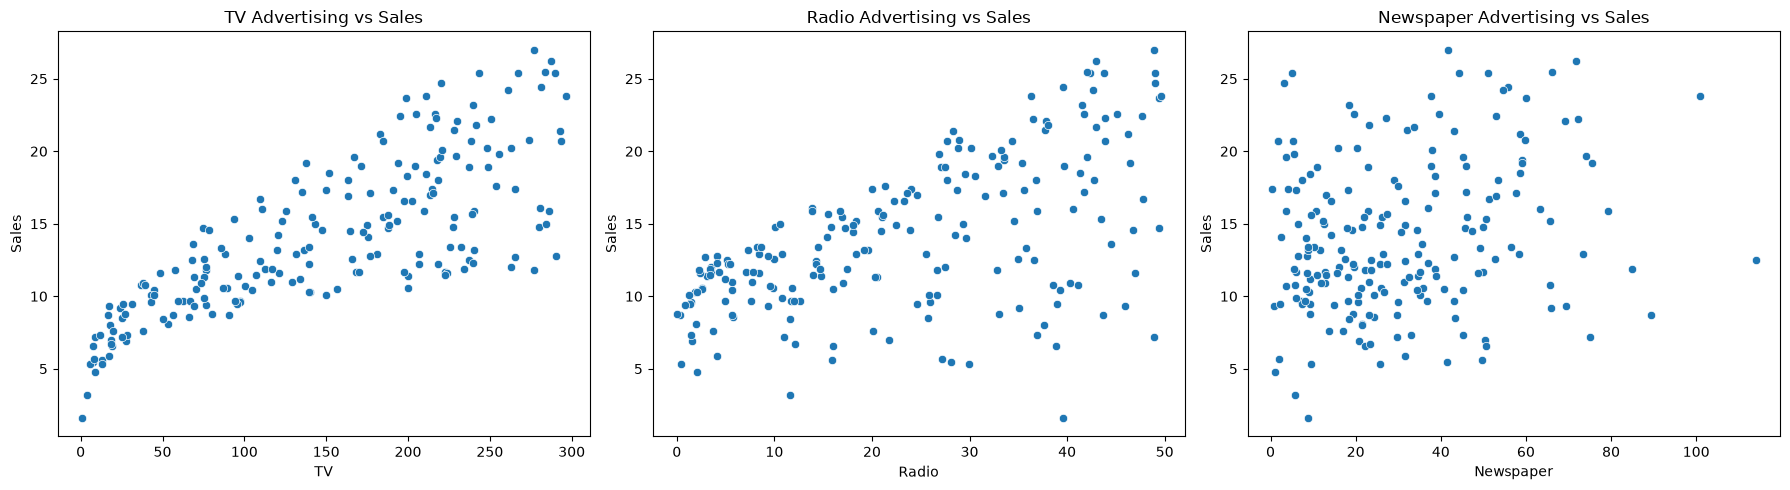

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x="TV", y="Sales", ax=axes[0])
axes[0].set_title("TV Advertising vs Sales")

sns.scatterplot(data=df, x="Radio", y="Sales", ax=axes[1])
axes[1].set_title("Radio Advertising vs Sales")

sns.scatterplot(data=df, x="Newspaper", y="Sales", ax=axes[2])
axes[2].set_title("Newspaper Advertising vs Sales")

plt.tight_layout()
plt.show()

In [7]:
correlation_matrix = df[["TV", "Radio", "Newspaper", "Sales"]].corr()

print("Correlation Matrix:")
print(correlation_matrix)

Correlation Matrix:
                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.782224
Radio      0.054809  1.000000   0.354104  0.576223
Newspaper  0.056648  0.354104   1.000000  0.228299
Sales      0.782224  0.576223   0.228299  1.000000


In [8]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (200, 3)
Target shape: (200,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


In [10]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Performance")
print("-" * 40)
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.2f}")

Linear Regression Performance
----------------------------------------
MAE  : 1.46
MSE  : 3.17
RMSE : 1.78
R²   : 0.90


In [12]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [13]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Performance")
print("-" * 40)
print(f"MAE  : {rf_mae:.2f}")
print(f"MSE  : {rf_mse:.2f}")
print(f"RMSE : {rf_rmse:.2f}")
print(f"R²   : {rf_r2:.2f}")

Random Forest Performance
----------------------------------------
MAE  : 0.63
MSE  : 0.57
RMSE : 0.76
R²   : 0.98


In [14]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print("Model Comparison:")
model_comparison

Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.629625,0.757357,0.981827


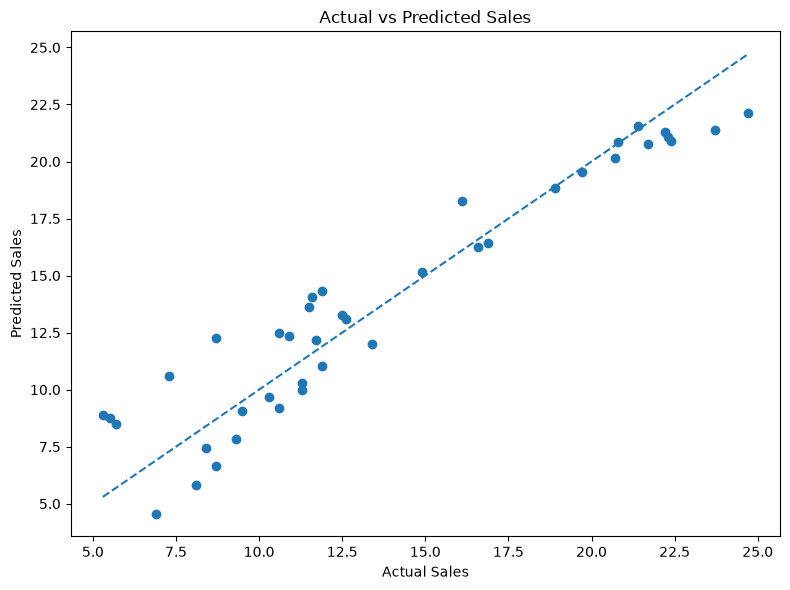

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.tight_layout()
plt.show()

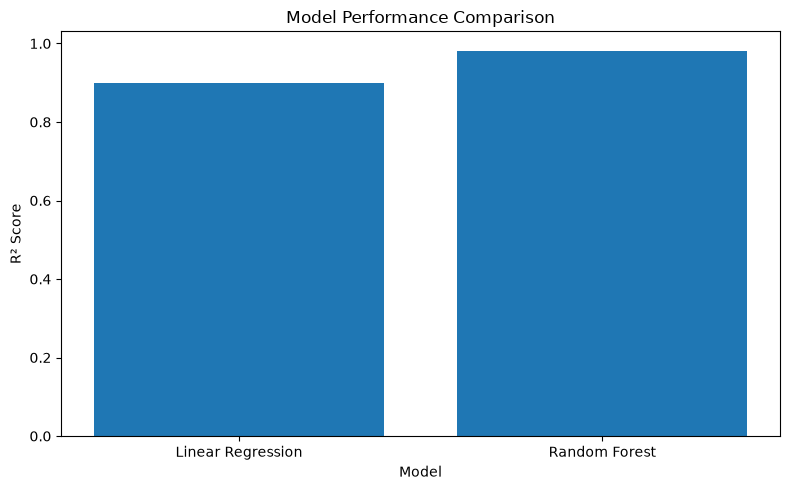

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["R2 Score"]
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.tight_layout()
plt.show()

In [17]:
sample_data = X_test.iloc[[0]]

actual_sales = y_test.iloc[0]
predicted_sales = linear_model.predict(sample_data)[0]

print("Sample Sales Prediction")
print("-" * 40)
print(f"Actual Sales    : {actual_sales:.2f}")
print(f"Predicted Sales : {predicted_sales:.2f}")
print(f"Difference      : {abs(actual_sales - predicted_sales):.2f}")

Sample Sales Prediction
----------------------------------------
Actual Sales    : 16.90
Predicted Sales : 16.41
Difference      : 0.49


In [18]:
print("SALES PREDICTION - FINAL SUMMARY")
print("=" * 50)

print(f"Total records: {len(df)}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

print("\nLinear Regression:")
print(f"  MAE  : {mae:.2f}")
print(f"  RMSE : {rmse:.2f}")
print(f"  R²   : {r2:.2f}")

print("\nRandom Forest:")
print(f"  MAE  : {rf_mae:.2f}")
print(f"  RMSE : {rf_rmse:.2f}")
print(f"  R²   : {rf_r2:.2f}")

SALES PREDICTION - FINAL SUMMARY
Total records: 200
Training samples: 160
Testing samples: 40

Linear Regression:
  MAE  : 1.46
  RMSE : 1.78
  R²   : 0.90

Random Forest:
  MAE  : 0.63
  RMSE : 0.76
  R²   : 0.98
